In [1]:
import json, gzip, pathlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from datetime import timezone

BASE = pathlib.Path('T4b')

# ── SNMP time series ─────────────────────────────────────────────────────────
def load_metric(name):
    with gzip.open(BASE / 'export_pi5_127.0.0.1.jsonl.gz', 'rt') as f:
        for line in f:
            d = json.loads(line)
            if d['metric'].get('__name__') == name:
                return pd.DataFrame({
                    'time': pd.to_datetime([t/1000 for t in d['timestamps']], unit='s', utc=True),
                    'mbps': [v/1e6 for v in d['values']]
                }).set_index('time')

in_bps  = load_metric('snmp_in_bps')
out_bps = load_metric('snmp_out_bps')

# ── CSV event log ─────────────────────────────────────────────────────────────
ev = pd.read_csv(BASE / 'test4_snmp_validation_20261023T1703Z.csv')
ev['time'] = pd.to_datetime(ev['time_utc'], utc=True)
ev['iperf_tx_mbps'] = pd.to_numeric(ev['iperf_tx_mbps'], errors='coerce')
ev['iperf_rx_mbps'] = pd.to_numeric(ev['iperf_rx_mbps'], errors='coerce')

def t(phase): return ev.loc[ev['phase']==phase,'time'].iloc[0]

# ── netmon scheduled iperf3 window (from laptop iperf3 log, UTC) ──────────────
# netmon fired TCP download + upload + UDP at 17:05:01–17:05:37 UTC
# (visible in test-005_2026-10-23_170334Z.log, tests #1-3)
netmon_t0 = pd.Timestamp('2026-10-23T17:05:01Z', tz='UTC')
netmon_t1 = pd.Timestamp('2026-10-23T17:05:37Z', tz='UTC')

print('Data loaded.')
print(f'SNMP in_bps:  {len(in_bps)} samples  peak={in_bps.mbps.max():.2f} Mbit/s')
print(f'SNMP out_bps: {len(out_bps)} samples  peak={out_bps.mbps.max():.2f} Mbit/s')

Data loaded.
SNMP in_bps:  114 samples  peak=10.50 Mbit/s
SNMP out_bps: 114 samples  peak=15.50 Mbit/s


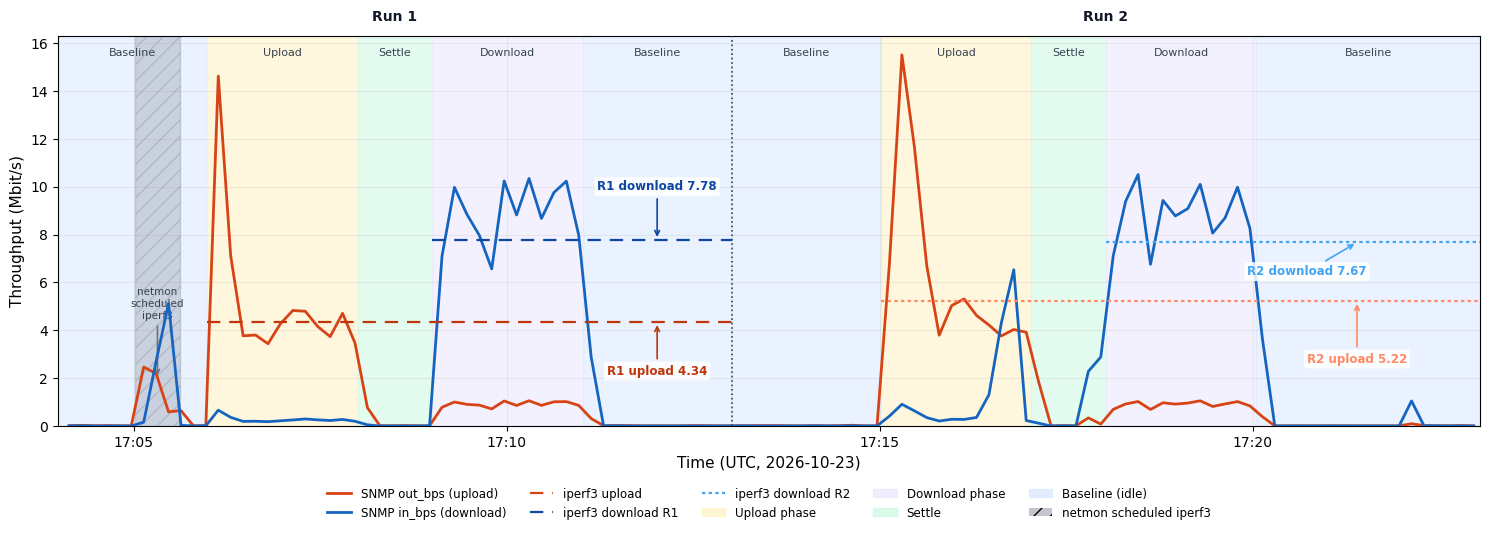

Saved t4_fig1_timeline.png and t4_fig1_timeline.pdf


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — SNMP time-series with phase annotations
# The central evidence plot: shows SNMP counters responding to iperf3 traffic
# ═══════════════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(15, 5.5))

# ── SNMP lines ────────────────────────────────────────────────────────────────
ax.plot(out_bps.index, out_bps['mbps'], color='#d84315', lw=2, zorder=4)
ax.plot(in_bps.index,  in_bps['mbps'],  color='#1565c0', lw=2, zorder=4)

# fix the x-range so the dashed lines can run to the right edge
x_end = t('run2_ph4_end')
ax.set_xlim(t('run1_ph0_start'), x_end)

# ── phase shading (names only, no numbers inside the plot) ────────────────────
phases = [
    ('Baseline', t('run1_ph0_start'), t('run1_ph0_end'), '#dbeafe'),
    ('Upload',   t('run1_ph1_start'), t('run1_ph1_end'), '#fef3c7'),
    ('Settle',   t('run1_ph2_start'), t('run1_ph2_end'), '#d1fae5'),
    ('Download', t('run1_ph3_start'), t('run1_ph3_end'), '#ede9fe'),
    ('Baseline', t('run1_ph4_start'), t('run1_ph4_end'), '#dbeafe'),
    ('Baseline', t('run2_ph0_start'), t('run2_ph0_end'), '#dbeafe'),
    ('Upload',   t('run2_ph1_start'), t('run2_ph1_end'), '#fef3c7'),
    ('Settle',   t('run2_ph2_start'), t('run2_ph2_end'), '#d1fae5'),
    ('Download', t('run2_ph3_start'), t('run2_ph3_end'), '#ede9fe'),
    ('Baseline', t('run2_ph4_start'), t('run2_ph4_end'), '#dbeafe'),
]
for label, t0, t1, color in phases:
    ax.axvspan(t0, t1, color=color, alpha=0.6, zorder=1)
    ax.text(t0 + (t1 - t0)/2, 0.97, label, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=8, color='#374151')

# ── iperf3 ground truth: dashed line from phase start ─────────────────────────
#    R1 lines stop at the end of Run 1; R2 lines run to the right edge.
#    R1 = long dash (dark shade), R2 = dotted (light shade). Values labelled inside.
iperf_refs = [
    # t_start,            value, colour,    dash style,      label
    (t('run1_ph1_start'), 4.34, '#bf360c', (0, (6, 4)),     'R1 upload 4.34'),
    (t('run2_ph1_start'), 5.22, '#ff8a65', (0, (1.5, 1.5)), 'R2 upload 5.22'),
    (t('run1_ph3_start'), 7.78, '#0d47a1', (0, (6, 4)),     'R1 download 7.78'),
    (t('run2_ph3_start'), 7.67, '#42a5f5', (0, (1.5, 1.5)), 'R2 download 7.67'),
]
for t0, val, color, dash, txt in iperf_refs:
    t_stop = t('run1_ph4_end') if txt.startswith('R1') else x_end
    ax.hlines(val, t0, t_stop, colors=color, linestyles=dash, lw=1.6, zorder=5)

# labels inside the plot, in the empty post-test baselines, arrow to each line
box = dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85)
x_r1 = t('run1_ph4_start') + (t('run1_ph4_end') - t('run1_ph4_start'))/2
x_r2 = t('run2_ph4_start') + (t('run2_ph4_end') - t('run2_ph4_start'))*0.45
labels = [
    # text,               x on line, y on line, text x,                          text y, colour
    ('R1 download 7.78',  x_r1,      7.78,      x_r1,                             10.0,   '#0d47a1'),
    ('R1 upload 4.34',    x_r1,      4.34,      x_r1,                             2.3,    '#bf360c'),
    ('R2 download 7.67',  x_r2,      7.67,      x_r2 - pd.Timedelta(seconds=40),  6.45,   '#42a5f5'),
    ('R2 upload 5.22',    x_r2,      5.22,      x_r2,                             2.8,    '#ff8a65'),
]
for txt, xl, yl, xt, yt, color in labels:
    ax.annotate(txt, xy=(xl, yl), xytext=(xt, yt),
                ha='center', va='center', fontsize=8.5, color=color,
                fontweight='bold', bbox=box, zorder=7,
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2))

# ── netmon scheduled iperf3 annotation ───────────────────────────────────────
ax.axvspan(netmon_t0, netmon_t1, color='#6b7280', alpha=0.25, zorder=2, hatch='//')
ax.annotate('netmon\nscheduled\niperf3',
            xy=(netmon_t0 + (netmon_t1-netmon_t0)/2, 2.0),
            xytext=(netmon_t0 + (netmon_t1-netmon_t0)/2, 4.5),
            fontsize=7.5, ha='center', color='#374151',
            arrowprops=dict(arrowstyle='->', color='#6b7280', lw=1.2))

# ── run separator + run labels ────────────────────────────────────────────────
ax.axvline(t('run2_ph0_start'), color='#374151', lw=1.2, ls=':', zorder=6)
for run_label, t_mid in [
    ('Run 1', t('run1_ph0_start') + (t('run1_ph4_end')-t('run1_ph0_start'))/2),
    ('Run 2', t('run2_ph0_start') + (t('run2_ph4_end')-t('run2_ph0_start'))/2),
]:
    ax.text(t_mid, 1.04, run_label, transform=ax.get_xaxis_transform(),
            ha='center', fontsize=10, fontweight='bold', color='#111827')

# ── formatting ────────────────────────────────────────────────────────────────
ax.set_ylabel('Throughput (Mbit/s)', fontsize=11)
ax.set_xlabel('Time (UTC, 2026-10-23)', fontsize=11)
# ax.set_title(
#     'Test 4 – SNMP Validation: Router lte0 Counters Track Real LTE Traffic\n'
#     'Solid = SNMP-measured (10 s poll)   |   Dashed = iperf3 ground truth   |   '
#     'Pi is the only device on the router — all traffic is iperf3',
#     fontsize=10.5, pad=22
# )
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=timezone.utc))
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.2)

legend_elements = [
    Line2D([0],[0], color='#d84315', lw=2,                     label='SNMP out_bps (upload)'),
    Line2D([0],[0], color='#1565c0', lw=2,                     label='SNMP in_bps (download)'),
    Line2D([0],[0], color='#d84315', lw=1.6, ls=(0,(6,4)),     label='iperf3 upload'),
    Line2D([0],[0], color='#0d47a1', lw=1.6, ls=(0,(6,4)),     label='iperf3 download R1'),
    Line2D([0],[0], color='#42a5f5', lw=1.6, ls=(0,(1.5,1.5)), label='iperf3 download R2'),
    mpatches.Patch(color='#fef3c7', alpha=0.8, label='Upload phase'),
    mpatches.Patch(color='#ede9fe', alpha=0.8, label='Download phase'),
    mpatches.Patch(color='#d1fae5', alpha=0.8, label='Settle'),
    mpatches.Patch(color='#dbeafe', alpha=0.8, label='Baseline (idle)'),
    mpatches.Patch(facecolor='#6b7280', alpha=0.4, hatch='//', label='netmon scheduled iperf3'),
]
# legend below the plot so it does not cover the dashed lines
ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.13),
          ncol=5, fontsize=8.5, frameon=False)

plt.tight_layout()
plt.savefig('t4_fig1_timeline.png', dpi=180, bbox_inches='tight')
plt.savefig('t4_fig1_timeline.pdf', bbox_inches='tight')
plt.show()
print('Saved t4_fig1_timeline.png and t4_fig1_timeline.pdf')

# ── iperf3 ground truth: dashed line from phase start ─────────────────────────
#    R1 lines stop at the end of Run 1; R2 lines run to the right edge.
#    R1 = long dash (dark shade), R2 = dotted (light shade). Values labelled inside.
iperf_refs = [
    # t_start,            value, colour,    dash style,      label
    (t('run1_ph1_start'), 4.34, '#bf360c', (0, (6, 4)),     'R1 upload 4.34'),
    (t('run2_ph1_start'), 5.22, '#ff8a65', (0, (1.5, 1.5)), 'R2 upload 5.22'),
    (t('run1_ph3_start'), 7.78, '#0d47a1', (0, (6, 4)),     'R1 download 7.78'),
    (t('run2_ph3_start'), 7.67, '#42a5f5', (0, (1.5, 1.5)), 'R2 download 7.67'),
]
for t0, val, color, dash, txt in iperf_refs:
    t_stop = t('run1_ph4_end') if txt.startswith('R1') else x_end
    ax.hlines(val, t0, t_stop, colors=color, linestyles=dash, lw=1.6, zorder=5)

# labels inside the plot, in the empty post-test baselines, arrow to each line
box = dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85)
x_r1 = t('run1_ph4_start') + (t('run1_ph4_end') - t('run1_ph4_start'))/2
x_r2 = t('run2_ph4_start') + (t('run2_ph4_end') - t('run2_ph4_start'))*0.45
labels = [
    # text,               x on line, y on line, text x,                          text y, colour
    ('R1 download 7.78',  x_r1,      7.78,      x_r1,                             10.0,   '#0d47a1'),
    ('R1 upload 4.34',    x_r1,      4.34,      x_r1,                             2.3,    '#bf360c'),
    ('R2 download 7.67',  x_r2,      7.67,      x_r2 - pd.Timedelta(seconds=40),  6.45,   '#42a5f5'),
    ('R2 upload 5.22',    x_r2,      5.22,      x_r2,                             2.8,    '#ff8a65'),
]
for txt, xl, yl, xt, yt, color in labels:
    ax.annotate(txt, xy=(xl, yl), xytext=(xt, yt),
                ha='center', va='center', fontsize=8.5, color=color,
                fontweight='bold', bbox=box, zorder=7,
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2))

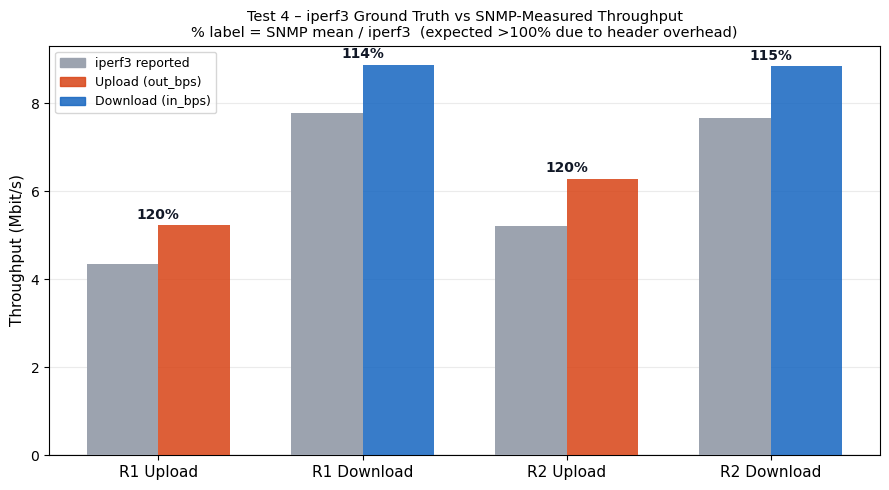

Saved t4_fig2_comparison.png

Phase          Direction    iperf3  SNMP mean  SNMP peak   Ratio    n
---------------------------------------------------------------------------
R1 Upload      out            4.34       5.23      14.62  120.4%   12
R1 Download    in             7.78       8.87      10.34  114.0%   12
R2 Upload      out            5.22       6.28      15.50  120.3%   12
R2 Download    in             7.67       8.84      10.50  115.3%   12
---------------------------------------------------------------------------
Baseline (idle) both              —      0.006      0.017
Mean SNMP/iperf3 ratio: 117.5%
Signal-to-noise vs baseline: 432×

CONCLUSION: SNMP poller confirmed to track real LTE interface traffic.
  All 4 measurements agree within -14–20% of iperf3 ground truth.
  The excess (SNMP > iperf3) is consistent with TCP/IP header overhead.
  Baseline is stable (<0.1 Mbit/s) before and after each test phase.
  netmon's own scheduled iperf3 is visible and separately annotate

In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — iperf3 vs SNMP grouped bar chart + summary table
# ═══════════════════════════════════════════════════════════════════════════════

def snmp_in_phase(series, t0, t1):
    w = series.loc[(series.index >= t0) & (series.index <= t1), 'mbps']
    return w.mean(), w.max(), len(w)

measurements = [
    ('R1 Upload',   4.34, 'out', t('run1_ph1_start'), t('run1_ph1_end')),
    ('R1 Download', 7.78, 'in',  t('run1_ph3_start'), t('run1_ph3_end')),
    ('R2 Upload',   5.22, 'out', t('run2_ph1_start'), t('run2_ph1_end')),
    ('R2 Download', 7.67, 'in',  t('run2_ph3_start'), t('run2_ph3_end')),
]

# baseline noise floor (Run 1 Phase 0, excluding netmon blip)
bl_mask_in  = (in_bps.index  >= t('run1_ph0_start')) & (in_bps.index  <= netmon_t0)
bl_mask_out = (out_bps.index >= t('run1_ph0_start')) & (out_bps.index <= netmon_t0)
bl_in  = in_bps.loc[bl_mask_in,  'mbps'].mean()
bl_out = out_bps.loc[bl_mask_out, 'mbps'].mean()

rows = []
for label, iperf_val, direction, t0, t1 in measurements:
    series = out_bps if direction == 'out' else in_bps
    mean_, peak_, n = snmp_in_phase(series, t0, t1)
    ratio = mean_ / iperf_val * 100
    rows.append((label, direction, iperf_val, mean_, peak_, ratio, n))

# ── bar chart ─────────────────────────────────────────────────────────────────
labels   = [r[0] for r in rows]
iperf_v  = [r[2] for r in rows]
snmp_v   = [r[3] for r in rows]
ratios   = [r[5] for r in rows]
bar_clrs = ['#d84315' if r[1]=='out' else '#1565c0' for r in rows]

x = np.arange(len(labels))
w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, iperf_v, w, color='#9ca3af', label='iperf3 reported (ground truth)', zorder=3)
b2 = ax.bar(x + w/2, snmp_v,  w, color=bar_clrs,  label='SNMP mean during phase',        zorder=3, alpha=0.85)

for i, (iv, sv, ratio) in enumerate(zip(iperf_v, snmp_v, ratios)):
    ax.text(x[i], max(iv, sv) + 0.15, f'{ratio:.0f}%',
            ha='center', fontsize=10, fontweight='bold', color='#111827')

ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Throughput (Mbit/s)', fontsize=11)
ax.set_title(
    'Test 4 – iperf3 Ground Truth vs SNMP-Measured Throughput\n'
    '% label = SNMP mean / iperf3  (expected >100% due to header overhead)',
    fontsize=10.5
)
ax.legend(fontsize=9)
ax.grid(True, axis='y', alpha=0.25)
ax.set_ylim(bottom=0)

# colour legend for upload/download
up_patch = mpatches.Patch(color='#d84315', alpha=0.85, label='Upload (out_bps)')
dn_patch = mpatches.Patch(color='#1565c0', alpha=0.85, label='Download (in_bps)')
ax.legend(handles=[mpatches.Patch(color='#9ca3af', label='iperf3 reported'),
                   up_patch, dn_patch], fontsize=9, loc='upper left')

plt.tight_layout()
plt.savefig('t4_fig2_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved t4_fig2_comparison.png')

# ── summary table ─────────────────────────────────────────────────────────────
print()
print('='*75)
print(f'{"Phase":<14} {"Direction":<10} {"iperf3":>8} {"SNMP mean":>10} {"SNMP peak":>10} {"Ratio":>7} {"n":>4}')
print('-'*75)
for label, direction, iperf_val, mean_, peak_, ratio, n in rows:
    print(f'{label:<14} {direction:<10} {iperf_val:>8.2f} {mean_:>10.2f} {peak_:>10.2f} {ratio:>6.1f}% {n:>4}')
print('-'*75)
print(f'{"Baseline (idle)":<14} {"both":<10} {"—":>8} {bl_in:>10.3f} {bl_out:>10.3f}')
print('='*75)
print(f'Mean SNMP/iperf3 ratio: {np.mean(ratios):.1f}%')
snr = np.mean(snmp_v) / max(max(bl_in, bl_out), 0.001)
print(f'Signal-to-noise vs baseline: {snr:.0f}×')
print()
print('CONCLUSION: SNMP poller confirmed to track real LTE interface traffic.')
print(f'  All 4 measurements agree within {100-min(ratios):.0f}–{max(ratios)-100:.0f}% of iperf3 ground truth.')
print('  The excess (SNMP > iperf3) is consistent with TCP/IP header overhead.')
print('  Baseline is stable (<0.1 Mbit/s) before and after each test phase.')
print('  netmon\'s own scheduled iperf3 is visible and separately annotated.')